lab 4. genetic algorithms, route optimization

AI Fundamentals and Applications

find short tour through 38 places in Djibouti. baseline is nearest neighbor, then GA with random start, GA with NN start, and tuned GA with NN start. compare length and time

0. libraries and data

In [1]:
import math, random, time, urllib.request
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

dataset dj38 from waterloo national TSP, downloads to data/ if not there

In [2]:
DATA = Path("data/dj38.tsp")
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://www.math.uwaterloo.ca/tsp/world/dj38.tsp", DATA)

1. load and plot locations

rows after NODE_COORD_SECTION are `ID x y`. node 1 is the depot, route starts and ends there

In [3]:
coords = {}
reading = False
for line in DATA.read_text().splitlines():
    line = line.strip()
    if line == "NODE_COORD_SECTION":
        reading = True
    elif reading and line and line != "EOF":
        node_id, x, y = line.split()
        coords[int(node_id)] = (float(x), float(y))

NODES = sorted(coords)
DEPOT = 1
print("locations:", len(NODES))
print("node 1:", coords[DEPOT])

locations: 38
node 1: (11003.6111, 42102.5)


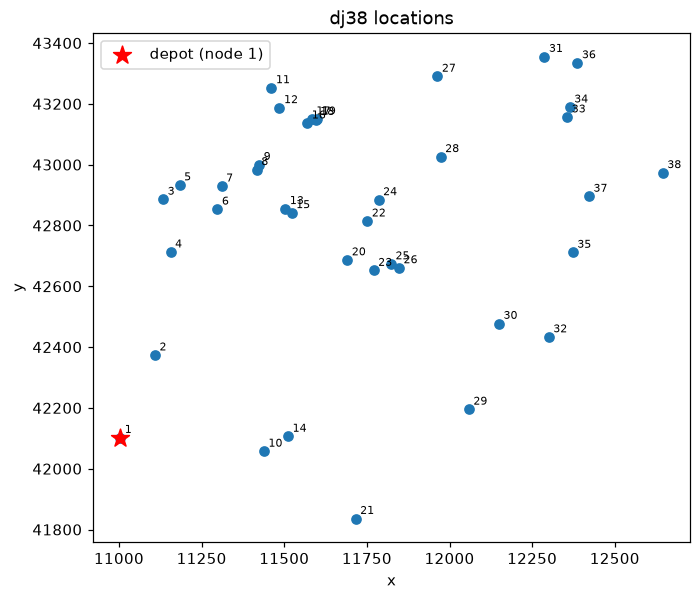

In [4]:
xs = [coords[n][0] for n in NODES]
ys = [coords[n][1] for n in NODES]

plt.figure(figsize=(7, 6))
plt.scatter(xs, ys, c="tab:blue")
for n in NODES:
    plt.annotate(str(n), coords[n], fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.scatter(*coords[DEPOT], c="red", s=150, marker="*", label="depot (node 1)", zorder=3)
plt.title("dj38 locations"); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

2. distance matrix and tour check

EUC_2D: straight line distance d, edge cost = int(d + 0.5).
tour = [1, ..., 1], every other node once. length = sum of all edges including way back to 1

In [5]:
dist = {}
for a in NODES:
    for b in NODES:
        d = math.dist(coords[a], coords[b])
        dist[a, b] = int(d + 0.5)

def tour_length(tour):
    return sum(dist[tour[i], tour[i + 1]] for i in range(len(tour) - 1))

def check_tour(tour):
    ok = (tour[0] == DEPOT and tour[-1] == DEPOT
          and len(tour) == len(NODES) + 1
          and sorted(tour[1:-1]) == [n for n in NODES if n != DEPOT])
    print("valid" if ok else "NOT valid", "| length:", tour_length(tour))

print("dist(1, 2) =", dist[1, 2])
check_tour([1] + list(range(2, 39)) + [1])   # simple test: 1, 2, 3, ..., 38, 1

dist(1, 2) = 291
valid | length: 17098


3. nearest neighbor baseline

start at 1, always go to closest unvisited node. tie -> smaller ID. then go back to 1

In [6]:
def nearest_neighbor():
    tour = [DEPOT]
    unvisited = [n for n in NODES if n != DEPOT]
    while unvisited:
        here = tour[-1]
        nxt = min(unvisited, key=lambda n: (dist[here, n], n))   # (distance, id) -> tie by smaller id
        tour.append(nxt)
        unvisited.remove(nxt)
    return tour + [DEPOT]

nn_tour = nearest_neighbor()
print(nn_tour)
check_tour(nn_tour)

[1, 2, 4, 3, 5, 7, 6, 8, 9, 13, 15, 20, 23, 25, 26, 22, 24, 28, 27, 31, 36, 34, 33, 37, 35, 32, 30, 29, 21, 14, 10, 16, 17, 18, 19, 12, 11, 38, 1]
valid | length: 9745


4. genetic algorithm

- chromosome = order of the 37 nodes without depot. full tour is [1] + chromosome + [1]
- fitness = tour length, smaller is better
- selection = tournament: take k random chromosomes, best one wins
- crossover = ordered crossover (OX): copy a piece from parent 1, fill the rest in parent 2 order. child is always a valid permutation
- mutation = swap two random cities, with probability mutation_rate
- elitism = 2 best go to next generation without change

population 80, 120 generations, so 80 + 120*80 = 9680 evaluations per run

In [7]:
def fitness(chrom):
    return tour_length([DEPOT] + chrom + [DEPOT])

def tournament(pop, scores, k, rng):
    picked = rng.sample(range(len(pop)), k)
    best = min(picked, key=lambda i: scores[i])
    return pop[best]

def ordered_crossover(p1, p2, rng):
    a, b = sorted(rng.sample(range(len(p1)), 2))
    child = [None] * len(p1)
    child[a:b + 1] = p1[a:b + 1]                       # piece from parent 1
    rest = [g for g in p2 if g not in child[a:b + 1]]  # other genes in parent 2 order
    for i in range(len(child)):
        if child[i] is None:
            child[i] = rest.pop(0)
    return child

def swap_mutation(chrom, rate, rng):
    chrom = chrom[:]
    if rng.random() < rate:
        i, j = rng.sample(range(len(chrom)), 2)
        chrom[i], chrom[j] = chrom[j], chrom[i]
    return chrom

In [8]:
def run_ga(seed, use_nn=False, pop_size=80, generations=120, tour_size=3,
           cx_prob=0.90, mut_rate=0.25, elites=2):
    rng = random.Random(seed)
    cities = [n for n in NODES if n != DEPOT]

    pop = [rng.sample(cities, len(cities)) for _ in range(pop_size)]
    if use_nn:
        pop[0] = nearest_neighbor()[1:-1]   # NN order without both depots

    scores = [fitness(c) for c in pop]
    evals = pop_size
    best_so_far = [min(scores)]             # generation 0

    for _ in range(generations):
        order = sorted(range(pop_size), key=lambda i: scores[i])
        new_pop = [pop[i][:] for i in order[:elites]]       # elitism
        while len(new_pop) < pop_size:
            p1 = tournament(pop, scores, tour_size, rng)
            p2 = tournament(pop, scores, tour_size, rng)
            child = ordered_crossover(p1, p2, rng) if rng.random() < cx_prob else p1[:]
            new_pop.append(swap_mutation(child, mut_rate, rng))
        pop = new_pop
        scores = [fitness(c) for c in pop]
        evals += pop_size
        best_so_far.append(min(best_so_far[-1], min(scores)))

    best = pop[min(range(pop_size), key=lambda i: scores[i])]
    return [DEPOT] + best + [DEPOT], best_so_far, evals

quick test of both variants with seed 0

In [9]:
for name, use_nn in [("default GA", False), ("NN-seeded GA", True)]:
    tour, hist, evals = run_ga(seed=0, use_nn=use_nn)
    print(name, "| evaluations:", evals, end=" | ")
    check_tour(tour)

default GA | evaluations: 9680 | valid | length: 11762


NN-seeded GA | evaluations: 9680 | valid | length: 8130


5. tuning NN-seeded GA

grid search over all 9 pairs: mutation rate 0.10/0.25/0.40 x tournament size 2/3/5. every pair runs with seeds 1, 2, 3.
pick lowest mean length. tie -> lower mutation rate, then smaller tournament

In [10]:
rows = []
for mut_rate, tour_size in product([0.10, 0.25, 0.40], [2, 3, 5]):
    lengths = []
    for seed in [1, 2, 3]:
        tour, _, _ = run_ga(seed, use_nn=True, mut_rate=mut_rate, tour_size=tour_size)
        lengths.append(tour_length(tour))
    rows.append({"mutation rate": mut_rate, "tournament size": tour_size,
                 "seed 1": lengths[0], "seed 2": lengths[1], "seed 3": lengths[2],
                 "mean": round(np.mean(lengths), 1)})

grid = pd.DataFrame(rows).sort_values(["mean", "mutation rate", "tournament size"]).reset_index(drop=True)
BEST_MUT = grid.loc[0, "mutation rate"]
BEST_TS = int(grid.loc[0, "tournament size"])
print(f"selected: mutation rate = {BEST_MUT}, tournament size = {BEST_TS}")
grid

selected: mutation rate = 0.1, tournament size = 2


,mutation rate,tournament size,seed 1,seed 2,seed 3,mean
0,0.10,2,8175,8044,8169,8129.3
1,0.25,2,8130,8130,8130,8130.0
2,0.40,3,8130,8130,8130,8130.0
3,0.40,5,8130,8130,8130,8130.0
4,0.25,3,8130,8131,8130,8130.3
5,0.40,2,8169,8130,8131,8143.3
6,0.10,3,8169,8170,8127,8155.3
7,0.25,5,8130,8244,8130,8168.0
8,0.10,5,8178,8244,8244,8222.0


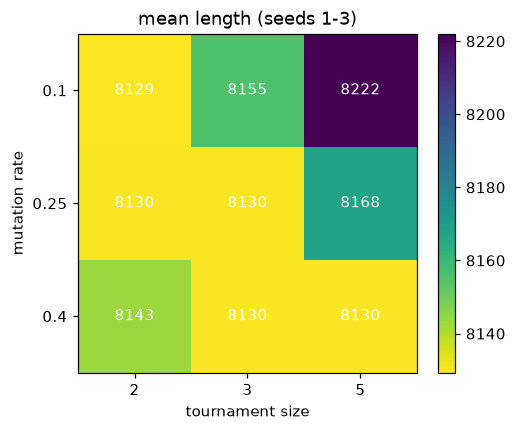

In [11]:
pivot = grid.pivot(index="mutation rate", columns="tournament size", values="mean")
plt.figure(figsize=(5, 4))
plt.imshow(pivot, cmap="viridis_r")
plt.xticks(range(3), pivot.columns); plt.yticks(range(3), pivot.index)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{pivot.iloc[i, j]:.0f}", ha="center", va="center", color="white")
plt.xlabel("tournament size"); plt.ylabel("mutation rate"); plt.title("mean length (seeds 1-3)")
plt.colorbar(); plt.show()

6. final comparison

all 3 GA variants with seeds 4, 5, 6. time with perf_counter, dist matrix is already built. seeded runs include making the NN tour (it is inside run_ga). NN runs once

In [12]:
start = time.perf_counter()
nn_tour = nearest_neighbor()
nn_time = time.perf_counter() - start
nn_len = tour_length(nn_tour)

variants = {
    "Default GA": dict(use_nn=False),
    "NN-seeded GA": dict(use_nn=True),
    "Tuned NN-seeded GA": dict(use_nn=True, mut_rate=BEST_MUT, tour_size=BEST_TS),
}

final = {}
for name, params in variants.items():
    final[name] = []
    for seed in [4, 5, 6]:
        start = time.perf_counter()
        tour, hist, _ = run_ga(seed, **params)
        sec = time.perf_counter() - start
        final[name].append({"seed": seed, "tour": tour, "length": tour_length(tour), "time": sec, "hist": hist})
        print(f"{name}, seed {seed}:", end=" ")
        check_tour(tour)

Default GA, seed 4: valid | length: 10906


Default GA, seed 5: valid | length: 9112
Default GA, seed 6: valid | length: 10513


NN-seeded GA, seed 4:

 valid | length: 8130
NN-seeded GA, seed 5: valid | length: 8130
NN-seeded GA, seed 6: valid | length: 8130


Tuned NN-seeded GA, seed 4: valid | length: 8133
Tuned NN-seeded GA, seed 5: valid | length: 8178
Tuned NN-seeded GA, seed 6: valid | length: 8218


In [13]:
settings = {
    "Nearest Neighbor": "depot 1",
    "Default GA": "random start",
    "NN-seeded GA": "default settings",
    "Tuned NN-seeded GA": f"mutation {BEST_MUT}, tournament {BEST_TS}",
}
table = [{"Method": "Nearest Neighbor", "Settings": settings["Nearest Neighbor"],
          "Best length": nn_len, "Mean length": nn_len, "Mean time (s)": round(nn_time, 5)}]
for name, runs in final.items():
    lengths = [r["length"] for r in runs]
    table.append({"Method": name, "Settings": settings[name],
                  "Best length": min(lengths), "Mean length": round(np.mean(lengths), 1),
                  "Mean time (s)": round(np.mean([r["time"] for r in runs]), 3)})
table = pd.DataFrame(table)
table

,Method,Settings,Best length,Mean length,Mean time (s)
0,Nearest Neighbor,depot 1,9745,9745.0,0.0001
1,Default GA,random start,9112,10177.0,0.1100
2,NN-seeded GA,default settings,8130,8130.0,0.1060
3,Tuned NN-seeded GA,"mutation 0.1, tournament 2",8133,8176.3,0.1040


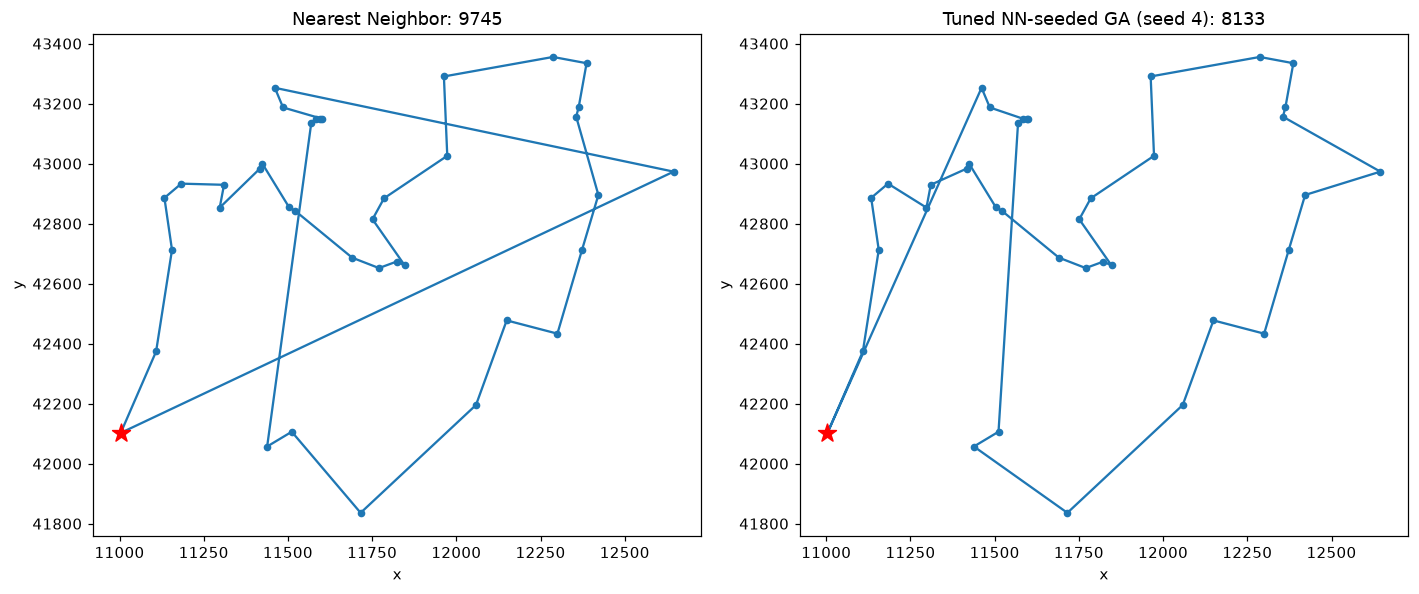

In [14]:
best_tuned = min(final["Tuned NN-seeded GA"], key=lambda r: r["length"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, tour, title in [(axes[0], nn_tour, f"Nearest Neighbor: {nn_len}"),
                        (axes[1], best_tuned["tour"], f"Tuned NN-seeded GA (seed {best_tuned['seed']}): {best_tuned['length']}")]:
    ax.plot([coords[n][0] for n in tour], [coords[n][1] for n in tour], "-o", ms=4)
    ax.scatter(*coords[DEPOT], c="red", s=150, marker="*", zorder=3)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

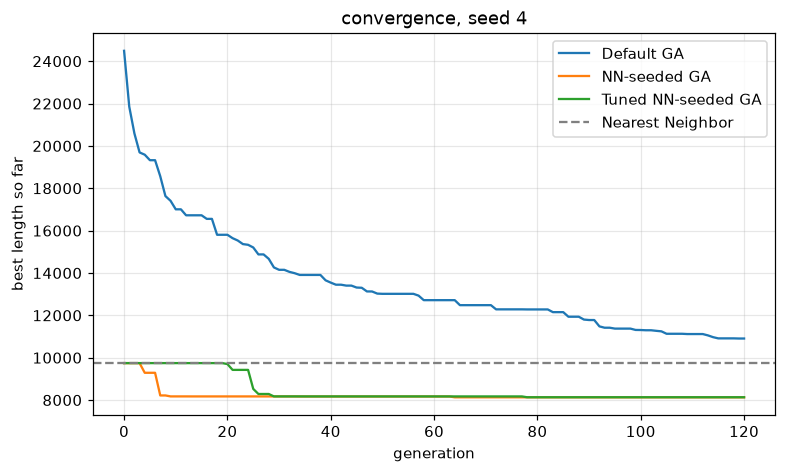

In [15]:
plt.figure(figsize=(8, 4.5))
for name, runs in final.items():
    run4 = [r for r in runs if r["seed"] == 4][0]
    plt.plot(run4["hist"], label=name)
plt.axhline(nn_len, color="gray", ls="--", label="Nearest Neighbor")
plt.xlabel("generation"); plt.ylabel("best length so far"); plt.title("convergence, seed 4")
plt.legend(); plt.grid(alpha=0.3); plt.show()

conclusion

shortest tour: NN-seeded GA with default settings, 8130 on all 3 seeds. tuned version best was 8133, default GA best 9112, NN 9745

seeding helps a lot. default GA mean 10177, NN-seeded mean 8130, about 2000 shorter. GA from random start in 120 gens doesnt even beat NN, but from NN start it improves NN by ~1600 (~17%). in convergence chart seeded GA is below NN from gen 0 and finds 8130 fast

tuning didnt help here. grid picked mutation 0.10 + tournament 2 (mean 8129.3), but it won only by 0.7 bc seed 2 was lucky (8044). on seeds 4-6 it got mean 8176.3, worse than default 8130. most pairs give ~8130 so differences are tiny and 3 seeds is too few to see real difference

time: NN is less than 1 ms, every GA ~0.1 s (9680 evaluations). seeding costs almost nothing extra bc NN is so fast. all GA tours still far from known optimum of dj38 (6656), would need more gens or 2-opt